# 10 · Simulación de variables aleatorias y teoremas de aproximación

La variable de Cauchy, la aproximación de la binomial por la Poisson, la ley exponencial y su relación con la geométrica, y cuatro formas de simular una variable geométrica.

**Contenido**

1. El teorema de simulación y la variable de Cauchy
2. Aproximación binomial–Poisson
3. La ley exponencial
4. De la geométrica a la exponencial
5. Cuatro métodos para simular una geométrica

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st

rng = np.random.default_rng(2026)

## 1. El teorema de simulación y la variable de Cauchy

**Teorema.** Sea $X$ una variable aleatoria real con función de distribución $F$ y sea $U\sim\mathrm{Unif}(0,1)$. Si $F$ es continua y estrictamente creciente, $F$ es una biyección de $\mathbb R$ sobre $(0,1)$ y $F^{-1}(U)$ tiene la misma ley que $X$. Si $F$ no es estrictamente creciente, el resultado sigue valiendo con la inversa generalizada

$$F^{-1}(u)=\inf\{x\in\mathbb R:\ F(x)\ge u\}$$

(cuaderno 09).

**Ejemplo (Cauchy).** La variable de Cauchy de parámetro $1$ tiene densidad $f(x)=\dfrac{1}{\pi}\dfrac{1}{1+x^2}$ y distribución $F(x)=\frac12+\frac1\pi\arctan x$. Para $u\in(0,1)$,

$$u=\frac1\pi\arctan x+\frac12\iff x=\tan\Big(\pi\big(u-\tfrac12\big)\Big).$$

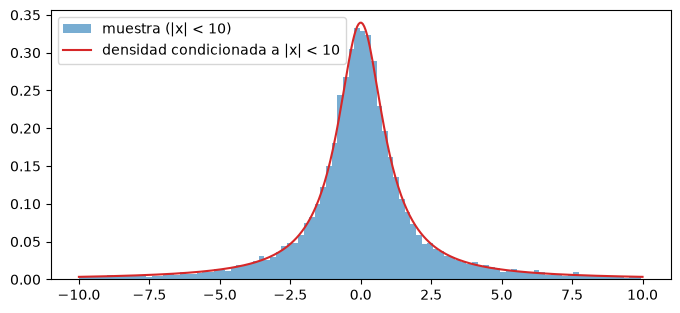

In [2]:
def cauchy(size):
    return np.tan(np.pi * (rng.random(size) - 0.5))

x = cauchy(20_000)
t = np.linspace(-10, 10, 400)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(x[np.abs(x) < 10], bins=100, density=True, alpha=0.6, label="muestra (|x| < 10)")
ax.plot(t, 1 / (np.pi * (1 + t**2)) / (2 / np.pi * np.arctan(10)), color="tab:red", label="densidad condicionada a |x| < 10")
ax.legend()
plt.show()

La variable de Cauchy no tiene esperanza: $\int|x|f(x)\,dx=\infty$. Por eso la ley de los grandes números no se aplica y las medias muestrales no se estabilizan. De hecho, $\bar X_n$ tiene de nuevo ley de Cauchy para todo $n$. La comparación con una normal es elocuente.

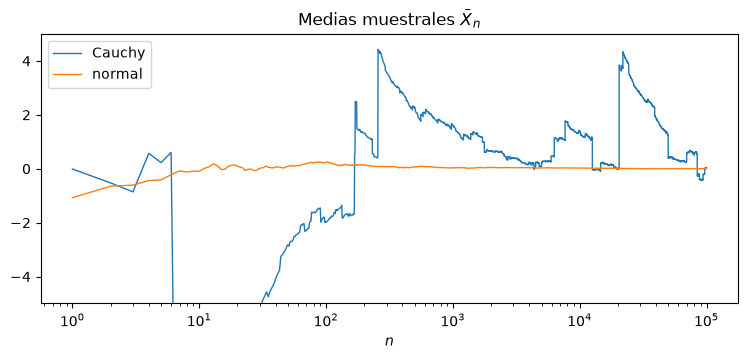

In [3]:
n = np.arange(1, 100_001)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(n, np.cumsum(cauchy(n.size)) / n, lw=1, label="Cauchy")
ax.plot(n, np.cumsum(rng.normal(size=n.size)) / n, lw=1, label="normal")
ax.set_xscale("log")
ax.set_ylim(-5, 5)
ax.set_xlabel("$n$")
ax.set_title(r"Medias muestrales $\bar X_n$")
ax.legend()
plt.show()

**Ejercicio.** Verifica que $f$ es una densidad de probabilidad.

## 2. Aproximación binomial–Poisson

**Teorema (Poisson).** Sea $S_n\sim\mathrm{Bin}(n,p_n)$ con $\lim_{n\to\infty}np_n=\theta>0$. Entonces, para todo $j\in\mathbb N$,

$$\lim_{n\to\infty}\mathbb P(S_n=j)=\lim_{n\to\infty}\binom nj p_n^j(1-p_n)^{n-j}=e^{-\theta}\frac{\theta^j}{j!}.$$

Es decir, $S_n$ converge en ley a una variable de Poisson de parámetro $\theta$: el número de éxitos de muchos ensayos con probabilidad pequeña de éxito.

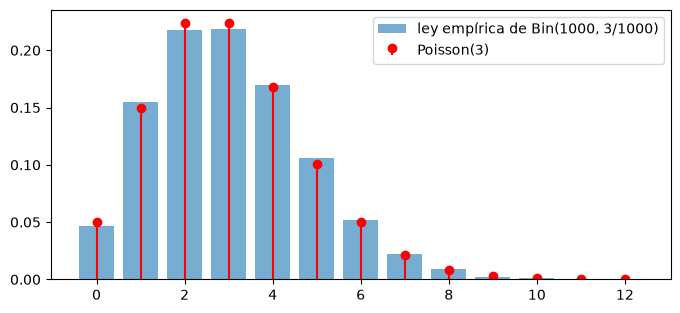

In [4]:
theta, n, N = 3, 1000, 5000
X = rng.binomial(n, theta / n, N)

conteos = np.bincount(X) / N
j = np.arange(len(conteos))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(j, conteos, width=0.8, alpha=0.6, label=f"ley empírica de Bin({n}, {theta}/{n})")
ax.stem(j, st.poisson.pmf(j, theta), linefmt="r-", markerfmt="ro", basefmt=" ", label=f"Poisson({theta})")
ax.legend()
plt.show()

La distancia en variación total $d_{TV}=\frac12\sum_j|\mathbb P(S_n=j)-\mathbb P(Y=j)|$ entre $\mathrm{Bin}(n,\theta/n)$ y $\mathrm{Poisson}(\theta)$ decrece como $1/n$ (la desigualdad de Le Cam da $d_{TV}\le\theta^2/n$).

In [5]:
j = np.arange(0, 60)
for n in [10, 100, 1000, 10_000]:
    dtv = 0.5 * np.abs(st.binom.pmf(j, n, theta / n) - st.poisson.pmf(j, theta)).sum()
    print(f"n = {n:>6}   d_TV = {dtv:.6f}   θ²/n = {theta**2 / n:.6f}")

n =     10   d_TV = 0.086409   θ²/n = 0.900000
n =    100   d_TV = 0.007607   θ²/n = 0.090000
n =   1000   d_TV = 0.000752   θ²/n = 0.009000
n =  10000   d_TV = 0.000075   θ²/n = 0.000900


La versión interactiva (Altair): elige $n$ y compara $\mathrm{Bin}(n,\theta/n)$ (barras) con $\mathrm{Poisson}(\theta)$ (puntos), con $\theta=3$.

In [6]:
import altair as alt
import pandas as pd

j = np.arange(0, 13)
datos = pd.concat([pd.DataFrame({"n": n, "j": j, "binomial": st.binom.pmf(j, n, theta / n), "poisson": st.poisson.pmf(j, theta)})
                   for n in [4, 6, 10, 20, 50, 100, 1000]])
n_sel = alt.param(name="n", value=6, bind=alt.binding_select(options=[4, 6, 10, 20, 50, 100, 1000], name="n: "))
base = alt.Chart(datos).transform_filter(alt.datum.n == n_sel).encode(x=alt.X("j:O", title="j"))
(base.mark_bar(opacity=0.6).encode(y=alt.Y("binomial:Q", title="probabilidad", scale=alt.Scale(domain=[0, 0.45])), tooltip=["j", "binomial"])
 + base.mark_point(filled=True, color="red", size=70).encode(y="poisson:Q", tooltip=["j", "poisson"])
).add_params(n_sel).properties(width=460, height=240, title="Bin(n, 3/n) contra Poisson(3)")

alt.LayerChart(...)

## 3. La ley exponencial

**Definición.** $X$ sigue una ley exponencial de parámetro $\lambda>0$ si $X(\Omega)=\mathbb R_+$ y $\mathbb P_X$ tiene densidad

$$f(x)=\lambda e^{-\lambda x}\mathbf 1_{\{x>0\}}.$$

Por el teorema de simulación, si $U\sim\mathrm{Unif}(0,1)$, entonces $X=-\dfrac{\ln U}{\lambda}\sim\exp(\lambda)$.

La ley exponencial modela duraciones: la vida de una bacteria, la duración de una llamada telefónica, el tiempo entre terremotos. Rutherford y Soddy la propusieron para la vida de los átomos radiactivos; ahí $\lambda$ se llama la **constante de desintegración**.

**Pérdida de memoria.** Para $s,t\ge 0$,

$$\mathbb P(X>t+s\mid X>t)=\mathbb P(X>s)=e^{-\lambda s}.$$

Recíprocamente, si $\rho(t)=\mathbb P(X>t)$ satisface $\rho(t+s)=\rho(t)\rho(s)$ y $\rho$ es derivable, derivando en $s=0$ se obtiene $\rho'(t)=-\lambda\rho(t)$ con $\lambda=-\rho'(0)\ge0$; como $\rho(0)=1$,

$$\rho(t)=e^{-\lambda t},\qquad f(t)=\lambda e^{-\lambda t}.$$

La exponencial es la única ley continua sin memoria.

In [7]:
lam, t0, s = 2.0, 0.7, 0.4
X = -np.log(rng.random(1_000_000)) / lam
condicional = np.mean(X[X > t0] > t0 + s)
print(f"P(X > t+s | X > t) ≈ {condicional:.4f},   P(X > s) = e^(-λs) = {np.exp(-lam * s):.4f}")

P(X > t+s | X > t) ≈ 0.4498,   P(X > s) = e^(-λs) = 0.4493


**Ejercicio.** Demuestra la propiedad de pérdida de memoria para $X\sim\exp(\lambda)$.

## 4. De la geométrica a la exponencial

**Teorema.** Para $\varepsilon>0$ sea $Y_\varepsilon\sim\mathrm{Geo}(p_\varepsilon)$ (número de ensayos hasta el primer éxito) con

$$\lim_{\varepsilon\to0}p_\varepsilon=0\qquad\text{y}\qquad \lim_{\varepsilon\to 0}\frac{p_\varepsilon}{\varepsilon}=\lambda>0.$$

Sea $X_\varepsilon=\varepsilon Y_\varepsilon$. Entonces $\lim_{\varepsilon\to0}F_{X_\varepsilon}(x)=F_X(x)$ para todo $x$, donde $X\sim\exp(\lambda)$: $X_\varepsilon$ converge en ley a una exponencial.

*Idea.* $\mathbb P(X_\varepsilon>x)=(1-p_\varepsilon)^{\lfloor x/\varepsilon\rfloor}\to e^{-\lambda x}$.

Visualizamos el teorema con $\varepsilon=1/n$ y $p_\varepsilon=\lambda/n$.

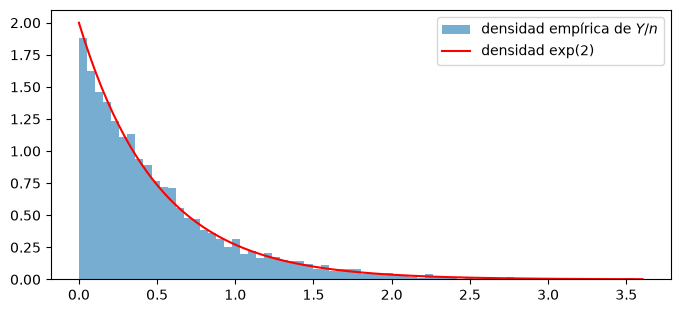

In [8]:
lam, n, N = 2, 1000, 5000
Y = rng.geometric(lam / n, N)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(Y / n, density=True, bins=int(np.sqrt(N)), alpha=0.6, label="densidad empírica de $Y/n$")
x = np.linspace(0, (Y / n).max(), 200)
ax.plot(x, lam * np.exp(-lam * x), "r", label=rf"densidad $\exp({lam})$")
ax.legend()
plt.show()

En sentido inverso:

**Teorema.** Sea $X\sim\exp(1)$, $\lambda>0$ y $Y=\lceil\lambda X\rceil=\min\{k\in\mathbb Z: k\ge\lambda X\}$. Entonces $Y\sim\mathrm{Geo}\big(p\big)$ con $p=1-e^{-1/\lambda}$.

*Demostración.* $\mathbb P(Y>k)=\mathbb P(X>k/\lambda)=e^{-k/\lambda}=(1-p)^k$ para $k\in\mathbb N$. $\blacksquare$

## 5. Cuatro métodos para simular una geométrica

Comparamos cuatro formas de simular $Y\sim\mathrm{Geo}(p)$, $\mathbb P(Y=k)=p(1-p)^{k-1}$ para $k\ge1$, a partir de uniformes:

1. **Inversión de la distribución discreta.** Para una variable entera con $\mathbb P(Y=k)=p_k$ se toma el $k$ tal que $p_1+\cdots+p_{k-1}<U\le p_1+\cdots+p_k$.
2. **Ensayos de Bernoulli.** Se generan ensayos ($1$ si $U<p$) y se para en el primer éxito.
3. **Exponencial.** Con $\lambda=-1/\ln(1-p)$ se toma $\lceil\lambda X\rceil$, $X\sim\exp(1)$. Equivale a la fórmula cerrada $Y=\left\lceil\dfrac{\ln U}{\ln(1-p)}\right\rceil$.
4. **El generador de NumPy**, `rng.geometric(p)`.

In [9]:
p, N = 0.2, 20_000


def metodo1():
    k, acumulada, U = 1, p, rng.random()
    while U > acumulada:
        acumulada += p * (1 - p) ** k
        k += 1
    return k


def metodo2():
    k = 1
    while rng.random() >= p:
        k += 1
    return k


def metodo3(size):
    X = -np.log(rng.random(size))
    return np.ceil(-X / np.log(1 - p)).astype(int)


def metodo4(size):
    return rng.geometric(p, size)


metodos = {
    "1 inversión (bucle)": lambda: np.array([metodo1() for _ in range(N)]),
    "2 Bernoulli (bucle)": lambda: np.array([metodo2() for _ in range(N)]),
    "3 exponencial (vectorizado)": lambda: metodo3(N),
    "4 rng.geometric": lambda: metodo4(N),
}
muestras = {}
for nombre, f in metodos.items():
    t0 = perf_counter()
    muestras[nombre] = f()
    print(f"{nombre:<30} {perf_counter() - t0:8.4f} s   media = {muestras[nombre].mean():.3f}  (1/p = {1 / p})")

1 inversión (bucle)              0.0500 s   media = 4.989  (1/p = 5.0)
2 Bernoulli (bucle)              0.1120 s   media = 4.986  (1/p = 5.0)
3 exponencial (vectorizado)      0.0006 s   media = 5.075  (1/p = 5.0)
4 rng.geometric                  0.0005 s   media = 4.999  (1/p = 5.0)


Los cuatro métodos producen la misma ley:

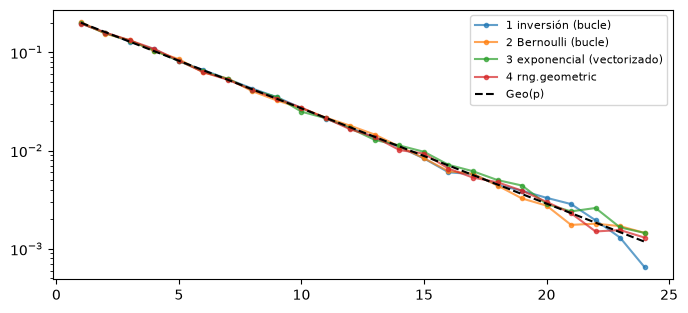

In [10]:
k = np.arange(1, 25)
fig, ax = plt.subplots(figsize=(8, 3.5))
for nombre, y in muestras.items():
    ax.plot(k, [np.mean(y == j) for j in k], ".-", alpha=0.7, label=nombre)
ax.plot(k, st.geom.pmf(k, p), "k--", label="Geo(p)")
ax.set_yscale("log")
ax.legend(fontsize=8)
plt.show()

El costo esperado de los métodos 1 y 2 crece como $1/p$ (número esperado de iteraciones), mientras que el método 3 usa una sola uniforme por muestra y se vectoriza. Los métodos 3 y 4 son los recomendables.

## Ejercicios

1. Demuestra que, en el método 1, $Y=k$ si y solo si $\dfrac{\ln(1-U)}{\ln(1-p)}\le k<\dfrac{\ln(1-U)}{\ln(1-p)}+1$.
2. Simula el teorema de Poisson con $p_n=\theta/n^{1/2}$. ¿Qué ocurre y por qué?